# BCCRI — Bank Customer Churn & Retention Intelligence

Autonomous walkthrough covering:
1. **Schema Validation & Edge-Case EDA** (`NumOfProducts` U-shape, `Balance == 0` Geography coupling, `HasCrCard == 0` vs `Card Type`)
2. **Target Leakage Audit & 3-Way Ablation** (`Complain` r = 0.9957 exclusion & `Satisfaction Score` sensitivity)
3. **Leak-Free 5-Fold Stratified CV & OOF Calibration** (`CatBoost`, `LightGBM`, `XGBoost`, `LogisticRegression`)
4. **OOF `shap.TreeExplainer` Actionable vs Static Decomposition & CRM Segments**
5. **Unit-Economics Retention ROI Simulation & 2D Break-Even Sensitivity**

In [1]:
import json
import os
import sys
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src.core.churn_config import ChurnPipelineConfig
from src.features.churn_feature_pipeline import build_clean_feature_matrix
from src.features.leakage_auditor import audit_target_leakage, summarize_satisfaction_alignment
from src.ingestion.kaggle_churn_loader import load_and_validate_churn_csv

config = ChurnPipelineConfig.create_default(PROJECT_ROOT)
bundle = load_and_validate_churn_csv(config.paths.raw_csv_path, config.partition)
print(f'Loaded {bundle.n_rows:,} rows x {bundle.n_cols} cols | Churn rate: {bundle.churn_rate*100:.2f}% | Zero-balance rate: {bundle.zero_balance_rate*100:.2f}%')

Loaded 10,000 rows x 18 cols | Churn rate: 20.38% | Zero-balance rate: 36.17%


## 1. Exploratory Structural Edge Cases

In [2]:
df = bundle.raw_df.copy()
prod_stats = df.groupby('NumOfProducts')['Exited'].agg(['count', 'mean']).rename(columns={'mean': 'churn_rate'})
geo_bal = df.assign(is_zero_balance=df['Balance'] == 0.0).groupby(['Geography', 'is_zero_balance'])['Exited'].agg(['count', 'mean'])
card_check = pd.crosstab(df['HasCrCard'], df['Card Type'])
display(prod_stats)
display(geo_bal)
display(card_check)

,count,churn_rate
NumOfProducts,,
1,5084,0.277144
2,4590,0.076035
3,266,0.827068
4,60,1.000000


count      mean
Geography is_zero_balance                 
France    False             2596  0.182589
          True              2418  0.139371
Germany   False             2509  0.324432
Spain     False             1278  0.195618
          True              1199  0.135947

Card Type,DIAMOND,GOLD,PLATINUM,SILVER
HasCrCard,,,,
0,732,763,731,719
1,1775,1739,1764,1777


## 2. Target Leakage Audit & 3-Way Ablation (`Complain` vs `Satisfaction Score`)

In [3]:
audit_rows = audit_target_leakage(bundle, config.partition, config.validation)
audit_df = pd.DataFrame([vars(r) for r in audit_rows])
sat_summary = summarize_satisfaction_alignment(df, config.partition)
display(audit_df)
print('Satisfaction Score alignment:', sat_summary)

results = json.loads(config.paths.results_json_path.read_text(encoding='utf-8'))
display(pd.DataFrame(results['leakage_audit']['ablation_table']))

,feature_name,pearson_corr,mutual_info,univariate_auc,is_flagged_leakage,disposition
0,Complain,0.995693,0.495726,0.998391,True,MANDATORY_EXCLUDE_POST_EVENT_LEAKAGE
1,Age,0.285296,0.068557,0.732076,False,INCLUDE_STATIC_CONTEXT
2,IsActiveMember,-0.156356,0.016454,0.596992,False,INCLUDE_ACTIONABLE_LEVER
3,Balance,0.118577,0.007427,0.577767,False,INCLUDE_ACTIONABLE_LEVER
4,Gender,-0.106267,0.005712,0.565669,False,INCLUDE_STATIC_CONTEXT
5,NumOfProducts,-0.047611,0.071585,0.578670,False,INCLUDE_ACTIONABLE_LEVER
6,Geography,0.035712,0.021771,0.534690,False,INCLUDE_STATIC_CONTEXT
7,CreditScore,-0.026771,0.004293,0.516292,False,INCLUDE_STATIC_CONTEXT
8,Tenure,-0.013656,0.000000,0.509761,False,INCLUDE_STATIC_CONTEXT
9,EstimatedSalary,0.012490,0.002705,0.508918,False,INCLUDE_STATIC_CONTEXT


Satisfaction Score alignment: {'mean_overall': 3.0138, 'mean_churned': 2.9975466143277725, 'mean_retained': 3.017960311479528, 'min_score_churn_rate': 0.19637610186092067, 'max_score_churn_rate': 0.217974180734856, 'pearson_r_exited': -0.005849198648614125}


,scenario_name,model_name,feature_count,roc_auc,pr_auc,f1_score,brier_score
0,leaky_with_complain,LogisticRegression,14,0.998936,0.996273,0.996570,0.001414
1,leaky_with_complain,LightGBM,14,0.999119,0.997877,0.996570,0.001394
2,no_complain_with_satisfaction,LogisticRegression,13,0.832273,0.622311,0.575536,0.115372
3,no_complain_with_satisfaction,LightGBM,13,0.863406,0.700572,0.622378,0.102364
4,strict_leak_free,LogisticRegression,12,0.832373,0.622340,0.577075,0.115365
5,strict_leak_free,LightGBM,12,0.863021,0.699423,0.622278,0.102500


## 3. Leak-Free 5-Fold Stratified CV Benchmark & OOF Calibration

In [4]:
clean_x, target_y = build_clean_feature_matrix(bundle.raw_df, config.partition)
print('Clean pre-event feature matrix shape:', clean_x.shape)
bench_df = pd.DataFrame(results['model_benchmark']).drop(columns=['fold_aucs'])
display(bench_df)

Clean pre-event feature matrix shape: (10000, 12)


,model_name,oof_roc_auc,oof_pr_auc,oof_f1_default,oof_f1_optimal,optimal_threshold,oof_brier,oof_ece,calibration_method,calibrated_brier,calibrated_ece
0,CatBoost,0.869421,0.712621,0.587379,0.635922,0.31,0.099970,0.006775,uncalibrated,0.099970,0.006775
1,LightGBM,0.863021,0.699423,0.571604,0.622278,0.34,0.102500,0.010725,platt_sigmoid,0.102491,0.008449
2,XGBoost,0.862844,0.699377,0.574741,0.620242,0.27,0.102479,0.011178,uncalibrated,0.102479,0.011178
3,LogisticRegression,0.832373,0.622340,0.495214,0.577075,0.28,0.115365,0.006187,uncalibrated,0.115365,0.006187


## 4. OOF SHAP Actionable vs Static Levers & CRM Retention Segments

In [5]:
shap_part = results['shap_lever_partition']
print(f"Actionable SHAP share: {shap_part['actionable_share']*100:.2f}% | Static share: {shap_part['static_share']*100:.2f}%")
shap_df = pd.Series(shap_part['feature_mean_abs_shap'], name='mean_abs_shap').sort_values(ascending=False).to_frame()
display(shap_df)
display(pd.DataFrame(shap_part['crm_segments']))

Actionable SHAP share: 52.22% | Static share: 47.78%


,mean_abs_shap
NumOfProducts,0.786818
Age,0.758438
IsActiveMember,0.379460
Gender,0.236781
Balance,0.217860
Geography,0.204245
EstimatedSalary,0.066562
Point Earned,0.052230
CreditScore,0.047682
Tenure,0.035093


,segment_name,client_count,client_share,mean_churn_prob,actual_churn_rate,mean_clv_eur,total_at_risk_clv_eur,recommended_action
0,Healthy / Low-Risk Monitor,8145,0.8145,0.099211,0.099079,2418.336404,2.319619e+06,Passive monitoring (no costly incentive)
1,Structural Demographic Risk,717,0.0717,0.684004,0.695955,3487.065910,1.691948e+06,Low-cost automated digital self-service retention
2,Product-Depth Reset,913,0.0913,0.644531,0.667032,2285.110188,1.396618e+06,Portfolio consolidation review to 2-product sw...
3,Dormancy Reactivation,139,0.0139,0.629486,0.604317,2727.250584,2.277081e+05,Omnichannel engagement nudge & loyalty point b...
4,Deposit & Card Retention,86,0.0086,0.504796,0.453488,4530.949636,2.005610e+05,Targeted deposit yield match or credit-card fe...


## 5. Retention ROI Simulation & 300 DPI Visual Synthesis

Optimal Policy: ev_lever_targeted_outreach @ f*=25% | Net ROI=+460,015 EUR (342.2% ROI) | Gain vs Risk-Ranked=+19,929 EUR


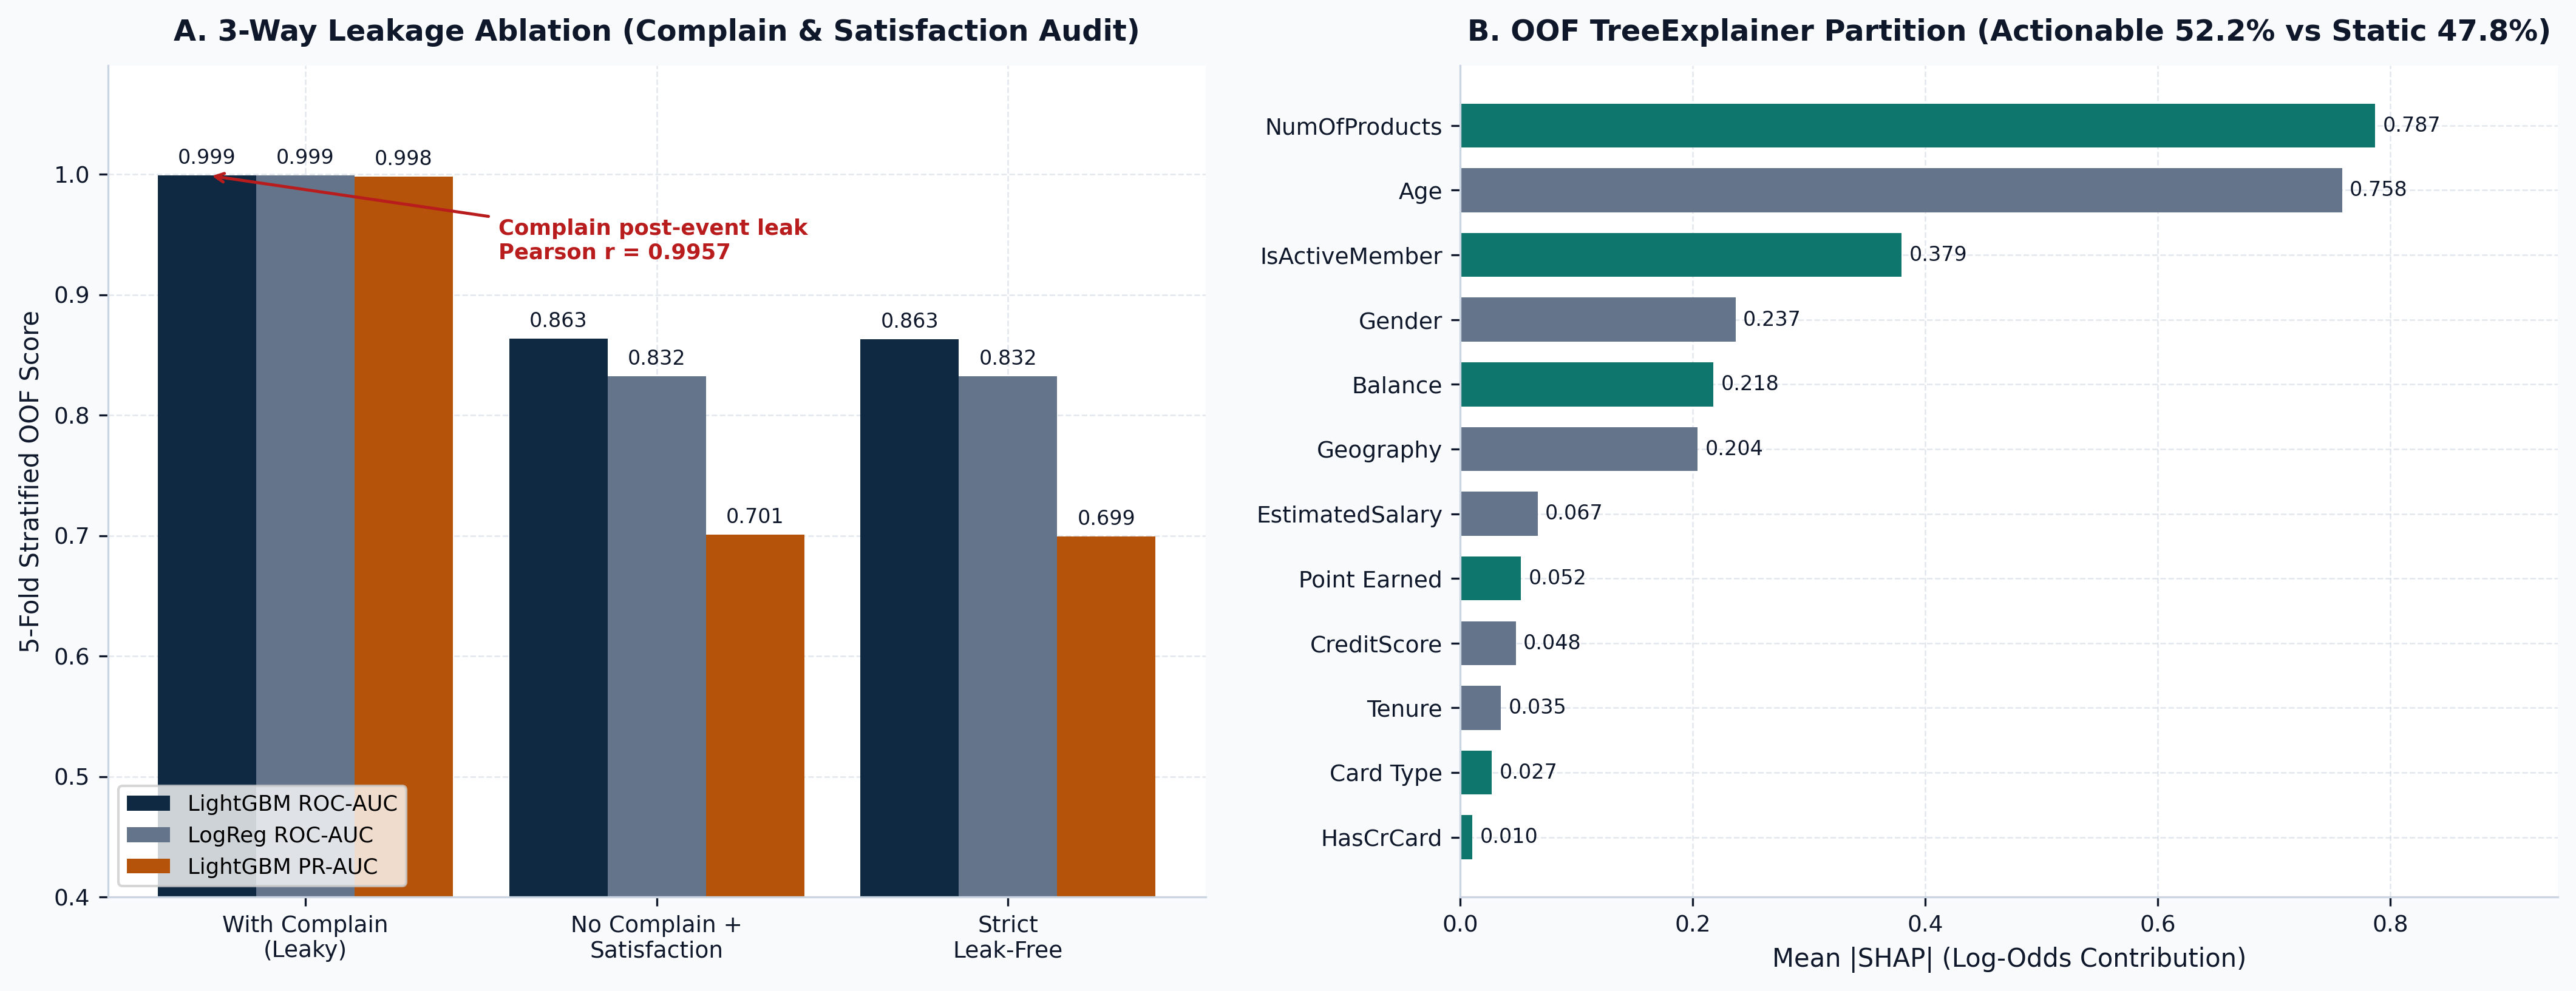

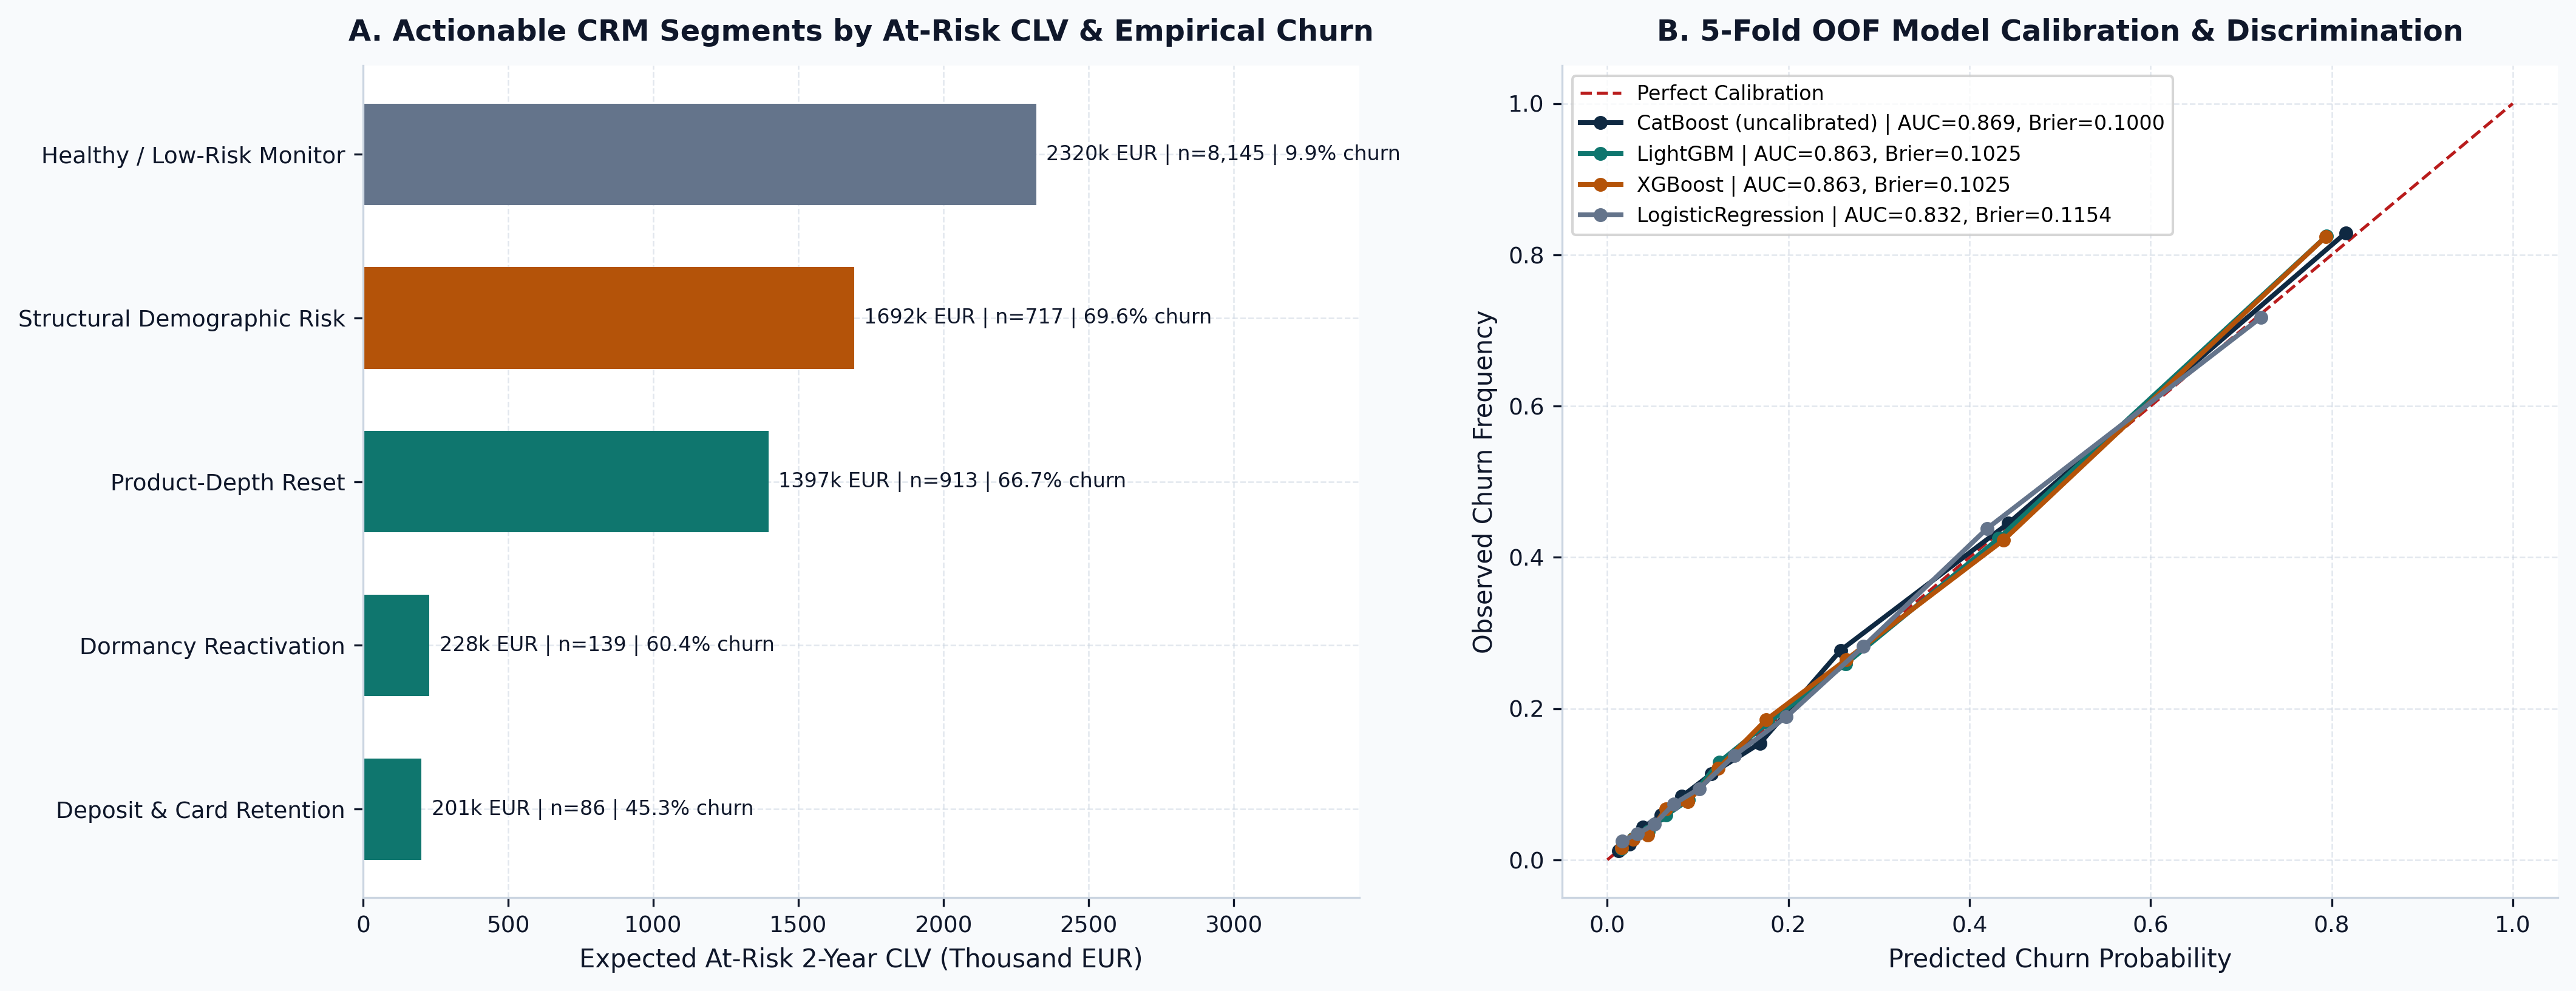

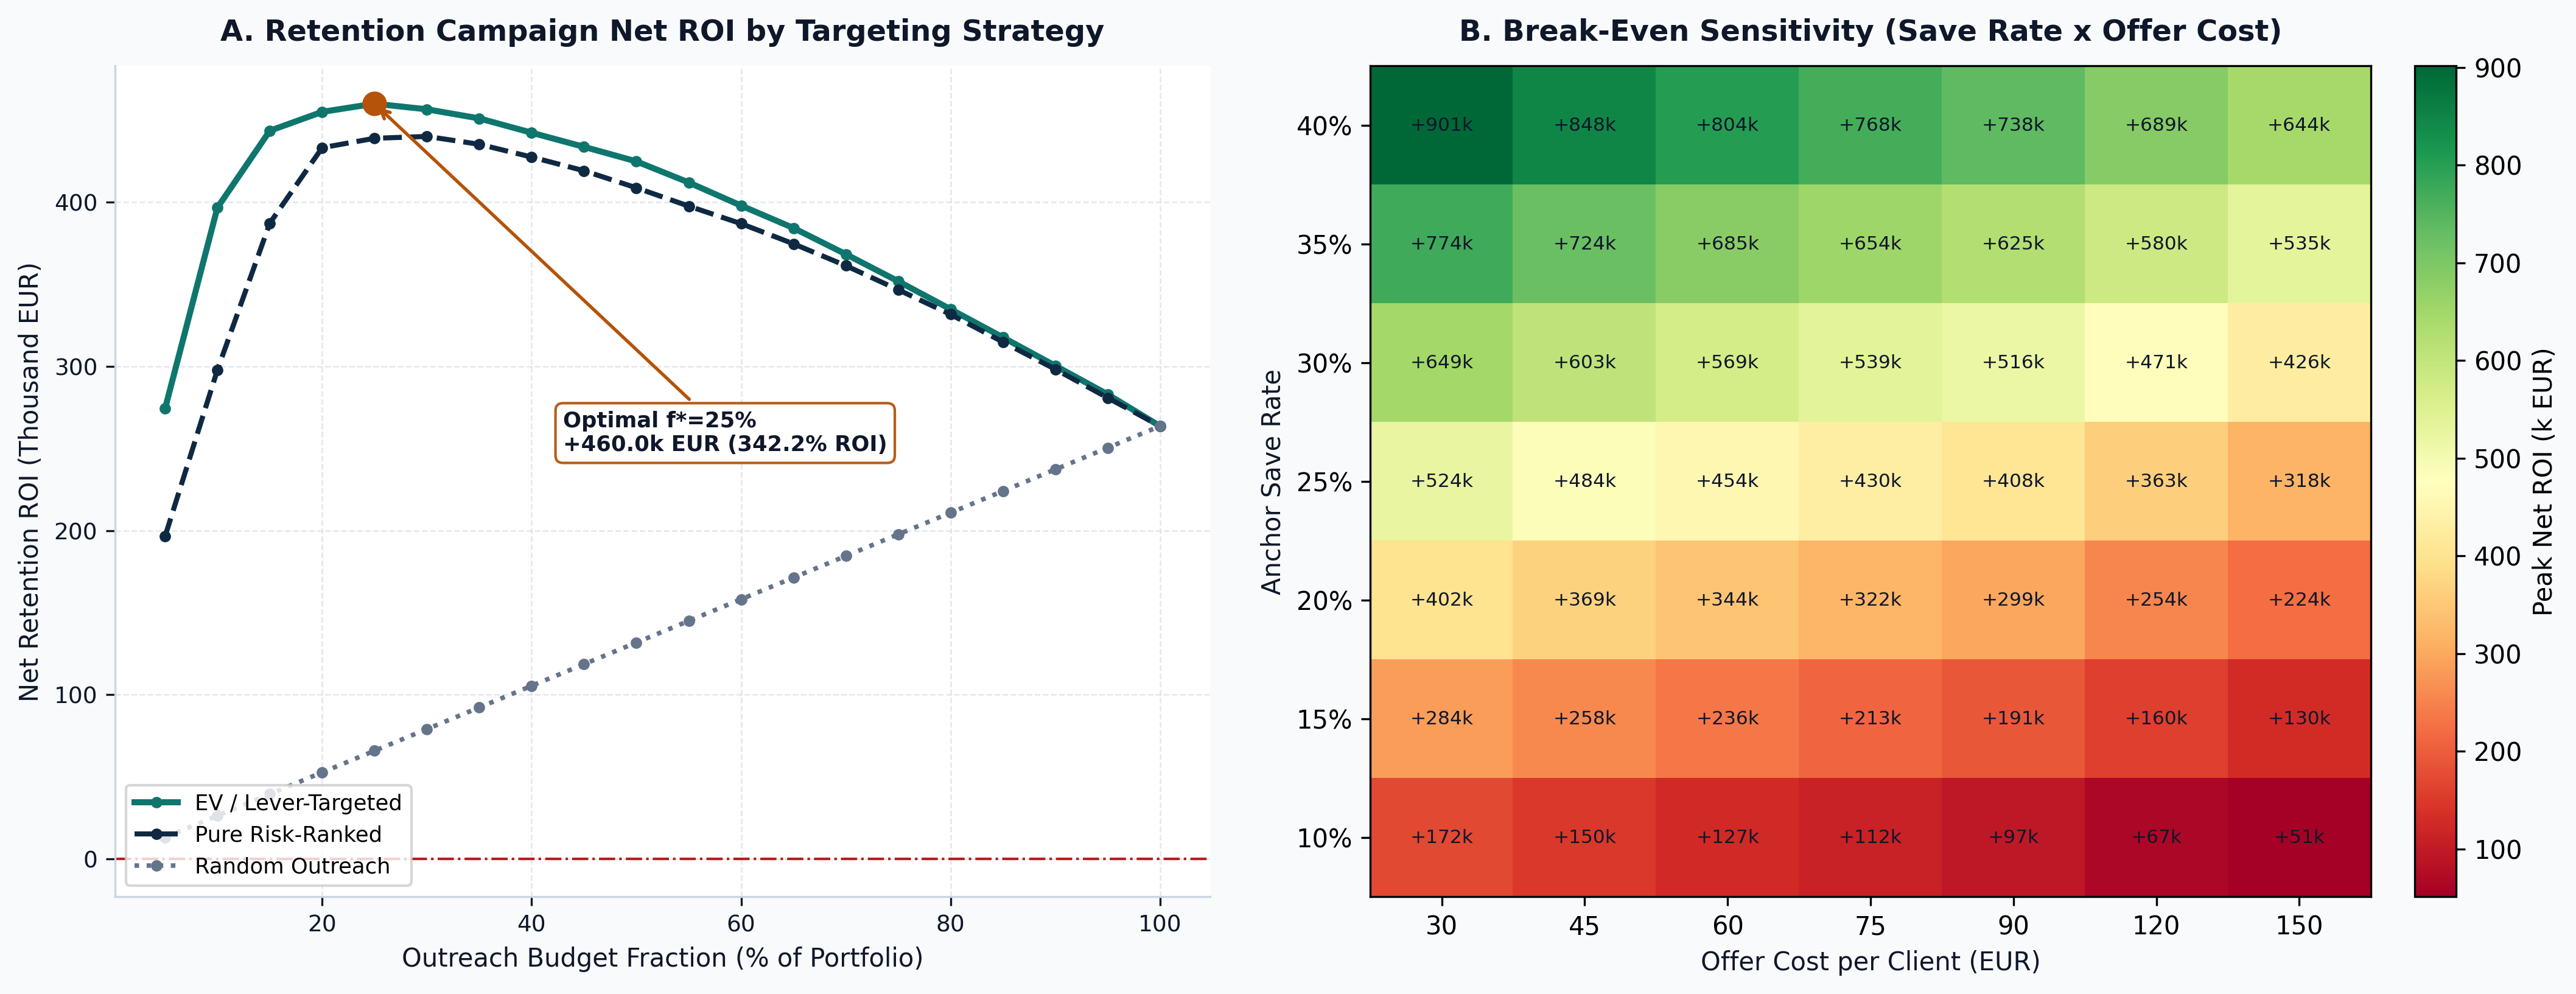

In [6]:
roi = results['retention_roi']
print(
    f"Optimal Policy: {roi['optimal_strategy']} @ f*={roi['optimal_outreach_fraction']*100:.0f}% "
    f"| Net ROI=+{roi['optimal_net_roi_eur']:,.0f} EUR ({roi['optimal_roi_pct']:.1f}% ROI) "
    f"| Gain vs Risk-Ranked=+{roi['ev_gain_over_risk_ranked_eur']:,.0f} EUR"
)
for fig_name in results['figures']:
    display(Image(filename=str(config.paths.images_dir / fig_name)))